In [1]:
# Código compartido del proyecto: Proyecto/codigo/merkle_wots.py
from merkle_wots import H, chain, WOTS, MerkleTree

In [2]:
import statistics
import time
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.asymmetric import ec

def benchmark_ecdsa(N=100):
    # Calentamiento
    for _ in range(10):
        sk = ec.generate_private_key(ec.SECP256R1())
        sig = sk.sign(b'test', ec.ECDSA(hashes.SHA256()))
        sk.public_key().verify(sig, b'test', ec.ECDSA(hashes.SHA256()))

    t_keygen, t_sign, t_verify = [], [], []

    for _ in range(N):
        t0 = time.perf_counter()
        sk = ec.generate_private_key(ec.SECP256R1())
        t1 = time.perf_counter()
        sig = sk.sign(b'mensaje_test', ec.ECDSA(hashes.SHA256()))
        t2 = time.perf_counter()
        sk.public_key().verify(sig, b'mensaje_test', ec.ECDSA(hashes.SHA256()))
        t3 = time.perf_counter()

        t_keygen.append((t1-t0)*1000)
        t_sign.append((t2-t1)*1000)
        t_verify.append((t3-t2)*1000)

    return {
        'keygen': (statistics.mean(t_keygen), statistics.stdev(t_keygen)),
        'sign': (statistics.mean(t_sign), statistics.stdev(t_sign)),
        'verify': (statistics.mean(t_verify), statistics.stdev(t_verify)),
        'sig_size': 64,
        'pk_size': 64,
    }

def benchmark_merkle(w, h=4, N=100):
    msg = b'mensaje_de_prueba_tel252'

    # Calentamiento

    tree_w = MerkleTree(h=h, w=w)
    sig_w = tree_w.sign(msg)
    MerkleTree.verify(tree_w.root, msg, sig_w, h=h, w=w)

    t_keygen, t_sign, t_verify = [], [], []

    for _ in range(N):
        t0 = time.perf_counter()
        tree = MerkleTree(h=h, w=w)
        t1 = time.perf_counter()
        sig = tree.sign(msg)
        t2 = time.perf_counter()
        ok = MerkleTree.verify(tree.root, msg, sig, h=h, w=w)
        t3 = time.perf_counter()

        assert ok
        t_keygen.append((t1-t0)*1000)
        t_sign.append((t2-t1)*1000)
        t_verify.append((t3-t2)*1000)

    return {
        'keygen': (statistics.mean(t_keygen), statistics.stdev(t_keygen)),
        'sign': (statistics.mean(t_sign), statistics.stdev(t_sign)),
        'verify': (statistics.mean(t_verify), statistics.stdev(t_verify)),
        'sig_size': len(sig_w),
        'pk_size': 32,
    }

N=10000
print(f"=== Ejecutando benchmarks N={N} ===")
ecdsa_res = benchmark_ecdsa(N)
print(
    f"ECDSA P-256 R1 -> Keygen: {ecdsa_res['keygen'][0]:.3f} ms, Sign:"
    f" {ecdsa_res['sign'][0]:.3f} ms, Verify: {ecdsa_res['verify'][0]:.3f} ms,"
    f" Size: {ecdsa_res['sig_size']} B"
)

merkle_res = {}
for w in [4, 16, 256]:
    res = benchmark_merkle(w=w, h=4, N=N)
    merkle_res[w] = res
    ratio_v = res['verify'][0] / ecdsa_res['verify'][0]
    print(
        f"Merkle (w={w}) -> Keygen: {res['keygen'][0]:.3f} ms, Sign:"
        f" {res['sign'][0]:.3f} ms, Verify: {res['verify'][0]:.3f} ms,"
        f" Size: {res['sig_size']} B | Ratio de verificaciones vs ECDSA {ratio_v:.2f} x"
    )

# Guarda media y desviación estándar para las tablas del informe
import json
with open('resultados.json', 'w') as f:
    json.dump({'N': N, 'ecdsa': ecdsa_res, 'merkle': {str(w): r for w, r in merkle_res.items()}}, f, indent=1)


=== Ejecutando benchmarks N=10000 ===


ECDSA P-256 R1 -> Keygen: 0.014 ms, Sign: 0.032 ms, Verify: 0.064 ms, Size: 64 B


Merkle (w=4) -> Keygen: 3.415 ms, Sign: 0.087 ms, Verify: 0.098 ms, Size: 4420 B | Ratio de verificaciones vs ECDSA 1.53 x


Merkle (w=16) -> Keygen: 5.251 ms, Sign: 0.158 ms, Verify: 0.163 ms, Size: 2308 B | Ratio de verificaciones vs ECDSA 2.53 x


Merkle (w=256) -> Keygen: 38.168 ms, Sign: 1.124 ms, Verify: 1.270 ms, Size: 1252 B | Ratio de verificaciones vs ECDSA 19.72 x


## Prueba de concepto (PoC)
16 firmas válidas, rechazo de mensaje alterado y rechazo de la firma #17.

In [3]:
def run_poc():
    print('=== PRUEBA DE CONCEPTO (PoC) - ÁRBOLES DE MERKLE (h=4) ===\n')
    tree = MerkleTree(h=4, w=16)
    root = tree.root
    print(f'1. Árbol generado con éxito. Raíz (PK Global): {root.hex()[:16]}...')
    print(f'   Capacidad total: 2^4 = {tree.num_leaves} firmas.\n')

    # A. Firmar 16 mensajes exitosamente
    print('2. Firmando 16 mensajes consecutivos...')
    firmas = []
    for i in range(16):
        msg = f'Transacción #{i+1}'.encode()
        sig = tree.sign(msg)
        valido = MerkleTree.verify(root, msg, sig, h=4, w=16)
        assert valido
        firmas.append(sig)
        print(f'   [OK] Mensaje {i+1:02d}/16 firmado y verificado con éxito. Size: {len(sig)}B')

    # B. Mensaje alterado con la firma original del mensaje #1
    print('\n3. Probar seguridad contra manipulación de mensaje...')
    msg_tampered = b'Transacci\xc3\xb3n #1 (ALTERADA POR MALORY)'
    valido_tampered = MerkleTree.verify(root, msg_tampered, firmas[0], h=4, w=16)
    print('   ¿Mensaje alterado verificado?:',
          'ACEPTADO (ERROR)' if valido_tampered else 'RECHAZADO (CORRECTO)')
    assert not valido_tampered

    # C. Intento de firmar el mensaje 17 (exceso de límite)
    print('\n4. Intentando firmar el mensaje #17 (agotamiento de claves)...')
    try:
        tree.sign('Transacción #17 - Ilegal'.encode())
        raise AssertionError('Se permitió firmar el mensaje 17.')
    except ValueError as e:
        print(f'   [ÉXITO] Transacción rechazada por el sistema. Excepción: {e}')

run_poc()


=== PRUEBA DE CONCEPTO (PoC) - ÁRBOLES DE MERKLE (h=4) ===

1. Árbol generado con éxito. Raíz (PK Global): 47a6930fd4ea8da4...
   Capacidad total: 2^4 = 16 firmas.

2. Firmando 16 mensajes consecutivos...
   [OK] Mensaje 01/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 02/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 03/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 04/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 05/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 06/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 07/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 08/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 09/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 10/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 11/16 firmado y verificado con éxito. Size: 2308B
   [OK] Mensaje 12/16 firmado y verificado con éxito. Size: 2308B
   

## Gráficos para el informe (datos medidos arriba)
- `../informe-tel252/figuras/tamano_tiempo_w.pdf` → Fig. (a), hipótesis 2: tamaño vs umbral 1/3 y tiempos vs umbral 10×, con la predicción ∝ nº de hashes.
- `../informe-tel252/figuras/comparacion_ecdsa.pdf` → Fig. (b), hipótesis 1: razones frente a ECDSA con las bandas de la hipótesis (w=16 destacado).

Hashes teóricos por verificación: [204.5, 507.5, 4340.0]
µs por hash al verificar: [0.481, 0.321, 0.293]
Razón tamaño w=256/w=4: 0.283 (umbral < 1/3)
Razón tiempo w=256/w=4: firmar 12.9x, verificar 12.9x (umbral > 10x)


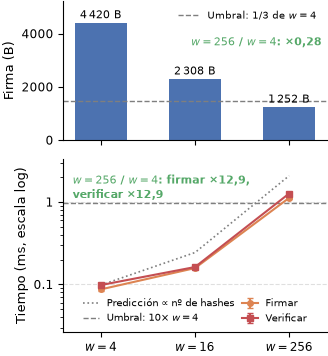

Tamaño / ECDSA: [69.1, 36.1, 19.6]
Verificar / ECDSA: [1.53, 2.53, 19.72]


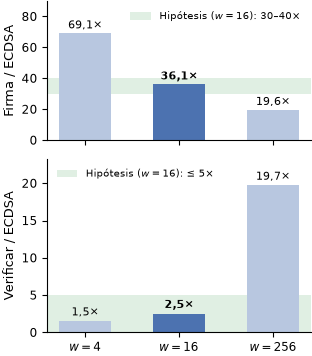

Gráficos PDF generados en figuras/


In [4]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Estilo para subfiguras de ~0,48\linewidth (Arial 12 en el texto)
plt.rcParams.update({
    'font.size': 9, 'font.family': 'sans-serif', 'axes.labelsize': 9,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 7.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})
FIG = '../informe-tel252/figuras'  # las figuras van directo al informe
os.makedirs(FIG, exist_ok=True)
coma = lambda v, d=1: f'{v:.{d}f}'.replace('.', ',')  # decimales en español

ws = [4, 16, 256]
xlab = [f'$w={w}$' for w in ws]
x = range(len(ws))
C_SIZE, C_SIGN, C_VER, C_REF, C_OK = '#4C72B0', '#DD8452', '#C44E52', '#7f7f7f', '#55A868'
colores_w = ['#b8c7e0', '#4C72B0', '#b8c7e0']  # w=16 (hipótesis 1) destacado

size = [merkle_res[w]['sig_size'] for w in ws]
sign_m = [merkle_res[w]['sign'][0] for w in ws];   sign_s = [merkle_res[w]['sign'][1] for w in ws]
ver_m = [merkle_res[w]['verify'][0] for w in ws];  ver_s = [merkle_res[w]['verify'][1] for w in ws]

# Hashes promedio por verificación: l(w-1)/2 + 1 + h (sección de análisis)
hashes = [WOTS(w).l * (w - 1) / 2 + 1 + 4 for w in ws]
print('Hashes teóricos por verificación:', hashes)
print('µs por hash al verificar:', [round(1000 * t / n, 3) for t, n in zip(ver_m, hashes)])
print(f'Razón tamaño w=256/w=4: {size[2]/size[0]:.3f} (umbral < 1/3)')
print(f'Razón tiempo w=256/w=4: firmar {sign_m[2]/sign_m[0]:.1f}x, verificar {ver_m[2]/ver_m[0]:.1f}x (umbral > 10x)')

# ---------------- FIGURA (a): efecto de w (hipótesis 2) ----------------
fig, (axs, axt) = plt.subplots(2, 1, figsize=(3.4, 4.3), sharex=True,
                               gridspec_kw={'height_ratios': [1, 1.25], 'hspace': 0.12})
axs.bar(x, size, color=C_SIZE, width=0.55)
umbral_s = size[0] / 3
axs.axhline(umbral_s, color=C_REF, ls='--', lw=1, label='Umbral: 1/3 de $w=4$')
axs.legend(loc='upper right', frameon=False)
for i, v in enumerate(size):
    axs.text(i, v + 60, f'{v:,} B'.replace(',', ' '), ha='center', va='bottom', fontsize=8)
axs.set_ylabel('Firma (B)')
axs.set_ylim(0, max(size) * 1.18)
axs.text(2.35, max(size) * 0.80, f'$w=256$ / $w=4$: ×{coma(size[2]/size[0], 2)}', ha='right',
         fontsize=8, fontweight='bold', color=C_OK)

axt.errorbar(x, sign_m, yerr=sign_s, color=C_SIGN, marker='o', ms=4, lw=1.5, capsize=2, label='Firmar')
axt.errorbar(x, ver_m, yerr=ver_s, color=C_VER, marker='s', ms=4, lw=1.5, capsize=2, label='Verificar')
pred = [ver_m[0] * n / hashes[0] for n in hashes]
axt.plot(x, pred, color=C_REF, ls=':', lw=1.2, label='Predicción ∝ nº de hashes')
axt.axhline(10 * ver_m[0], color=C_REF, ls='--', lw=1, label='Umbral: 10× $w=4$')
axt.set_yscale('log')
axt.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
axt.set_ylabel('Tiempo (ms, escala log)')
axt.set_xticks(list(x), xlab)
axt.set_xlim(-0.4, 2.4)
axt.set_ylim(min(sign_m) * 0.3, max(pred) * 1.6)
axt.text(-0.3, max(pred) * 1.05, f'$w=256$ / $w=4$: firmar ×{coma(sign_m[2]/sign_m[0])},\nverificar ×{coma(ver_m[2]/ver_m[0])}',
         fontsize=8, fontweight='bold', color=C_OK, va='top')
axt.legend(loc='lower center', ncol=2, frameon=False, columnspacing=0.8, handlelength=1.6, fontsize=7)
axt.grid(axis='y', which='major', ls='--', alpha=0.4)
fig.savefig(f'{FIG}/tamano_tiempo_w.pdf')
plt.show()

# ---------------- FIGURA (b): frente a ECDSA P-256 (hipótesis 1) ----------------
r_size = [s / ecdsa_res['sig_size'] for s in size]
r_ver = [v / ecdsa_res['verify'][0] for v in ver_m]
print('Tamaño / ECDSA:', [round(r, 1) for r in r_size])
print('Verificar / ECDSA:', [round(r, 2) for r in r_ver])

fig, (axs, axt) = plt.subplots(2, 1, figsize=(3.4, 4.3), sharex=True,
                               gridspec_kw={'height_ratios': [1, 1.25], 'hspace': 0.12})
axs.axhspan(30, 40, color=C_OK, alpha=0.18, lw=0, label='Hipótesis ($w=16$): 30–40×')
axs.legend(loc='upper right', frameon=False)
axs.bar(x, r_size, color=colores_w, width=0.55)
for i, v in enumerate(r_size):
    axs.text(i, v + 1.5, f'{coma(v)}×', ha='center', va='bottom', fontsize=8,
             fontweight='bold' if ws[i] == 16 else 'normal')
axs.set_ylabel('Firma / ECDSA')
axs.set_ylim(0, max(r_size) * 1.3)

axt.axhspan(0, 5, color=C_OK, alpha=0.18, lw=0, label='Hipótesis ($w=16$): ≤ 5×')
axt.legend(loc='upper left', frameon=False)
axt.bar(x, r_ver, color=colores_w, width=0.55)
for i, v in enumerate(r_ver):
    axt.text(i, v + 0.4, f'{coma(v)}×', ha='center', va='bottom', fontsize=8,
             fontweight='bold' if ws[i] == 16 else 'normal')
axt.set_ylabel('Verificar / ECDSA')
axt.set_ylim(0, max(r_ver) * 1.18)
axt.set_yticks([0, 5, 10, 15, 20])
axt.set_xticks(list(x), xlab)
fig.savefig(f'{FIG}/comparacion_ecdsa.pdf')
plt.show()
print(f'Gráficos PDF generados en {FIG}/')
